# Machine Learning Tasks
This notebook demonstrates two major tasks:
1. **Classification Task**: Predicting whether a tumor is benign or malignant using the Breast Cancer dataset and Support Vector Classifier (SVC).
2. **Regression Task**: Predicting concrete compressive strength using the Concrete Compressive Strength dataset and Random Forest Regressor.

## Part 1: Classification Task (Breast Cancer Dataset)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1. Load the Dataset
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = cancer.target

print("Features shape:", X.shape)
print("Target distribution:", np.bincount(y))
display(X.head())

Features shape: (569, 30)
Target distribution: [212 357]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
# 2. Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train a Classification Model (SVM)
model_cls = SVC(kernel='linear', random_state=42)
model_cls.fit(X_train, y_train)

# 4. Make Predictions
y_pred_cls = model_cls.predict(X_test)

Classification Accuracy: 0.9561

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



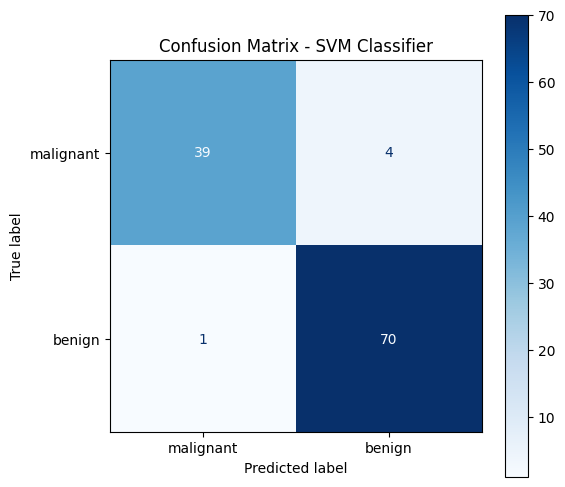

In [3]:
# 5. Evaluate the Model
accuracy = accuracy_score(y_test, y_pred_cls)
print(f"Classification Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_cls, target_names=cancer.target_names))

# Visualize Confusion Matrix
cm = confusion_matrix(y_test, y_pred_cls)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title("Confusion Matrix - SVM Classifier")
plt.show()

## Part 2: Regression Task (Concrete Compressive Strength Dataset)

In [4]:
import urllib.request
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load the Dataset from UCI Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
local_file = "Concrete_Data.xls"

try:
    print("Downloading Concrete dataset from UCI...")
    urllib.request.urlretrieve(url, local_file)
    df_concrete = pd.read_excel(local_file)
except Exception as e:
    print("Could not download Excel file, attempting to load from local directory:", e)
    # If the file is already placed in the current directory or a 'lesson' folder
    try:
        df_concrete = pd.read_excel('Concrete_Data.xls')
    except Exception as e2:
        raise FileNotFoundError("Please ensure 'Concrete_Data.xls' is accessible.") from e2

# Display basic information
display(df_concrete.head())
print(df_concrete.info())

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)  

In [7]:
# Prepare Features and Target
# The target is typically the last column: 'Concrete compressive strength(MPa, megapascals) '
X_reg = df_concrete.iloc[:, :-1]
y_reg = df_concrete.iloc[:, -1]

# 2. Perform Train-Test Split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# 3. Train a Regression Model
model_reg = RandomForestRegressor(n_estimators=100, random_state=42)
model_reg.fit(X_train_reg, y_train_reg)

# 4. Make Predictions
y_pred_reg = model_reg.predict(X_test_reg)

Mean Squared Error (MSE): 30.3581
R² Score: 0.8822


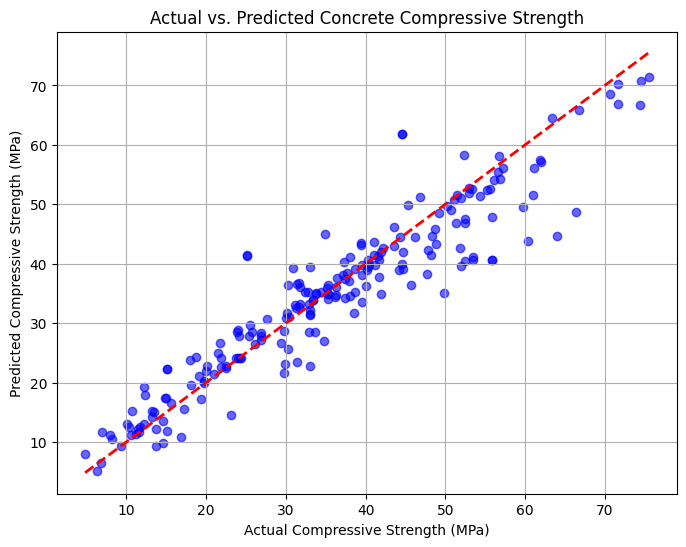

In [6]:
# 5. Evaluate the Model
mse = mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.6, color='b')
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.xlabel('Actual Compressive Strength (MPa)')
plt.ylabel('Predicted Compressive Strength (MPa)')
plt.title('Actual vs. Predicted Concrete Compressive Strength')
plt.grid(True)
plt.show()